# Phase 1: Brain MRI Dataset Inspection & Exploration

## Objective
The objective of this notebook is to perform a comprehensive, non-destructive audit of the original Brain Tumor MRI dataset. 
In this project, our primary restoration task focuses on restoring degraded MRI scans back to pristine diagnostic quality.

**Key Scope Requirement:**
- The **`notumor`** category serves as our clean reference / ground-truth benchmark.
- In this phase, **no degradations or restoration models** are generated. We strictly inspect and analyze the raw dataset properties:
  1. Image counts across splits (Training vs. Testing) and classes (`glioma`, `meningioma`, `notumor`, `pituitary`)
  2. File formats and integrity (checking for corrupted/unreadable files)
  3. Image dimensions and aspect ratios
  4. Color spaces and channel consistency (RGB vs. Grayscale L)
  5. Pixel intensity ranges and statistical distributions
  6. Visual inspection of representative samples from each class


In [1]:
import os
import glob
from pathlib import Path
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

# Configuration & Paths
DATASET_DIR = Path(r"C:\Users\gitan\BrainMRI_Project\dataset\archive")
TRAIN_DIR = DATASET_DIR / "Training"
TEST_DIR = DATASET_DIR / "Testing"
CATEGORIES = ["glioma", "meningioma", "notumor", "pituitary"]

print(f"Dataset Directory: {DATASET_DIR}")
print(f"Training Directory Exists: {TRAIN_DIR.exists()}")
print(f"Testing Directory Exists: {TEST_DIR.exists()}")


Dataset Directory: C:\Users\gitan\BrainMRI_Project\dataset\archive
Training Directory Exists: True
Testing Directory Exists: True


## 1. Image Count Analysis across Splits & Categories
We first count every image across both `Training` and `Testing` splits for all four tumor categories.


In [2]:
count_data = []

for split_name, split_path in [("Training", TRAIN_DIR), ("Testing", TEST_DIR)]:
    for cat in CATEGORIES:
        cat_path = split_path / cat
        img_files = list(cat_path.glob("*.*"))
        count_data.append({
            "Split": split_name,
            "Category": cat,
            "Count": len(img_files)
        })

df_counts = pd.DataFrame(count_data)
pivot_counts = df_counts.pivot(index="Category", columns="Split", values="Count")
pivot_counts["Total"] = pivot_counts["Training"] + pivot_counts["Testing"]
pivot_counts.loc["Total"] = pivot_counts.sum()

print("=== Dataset Image Counts ===")
print(pivot_counts)


=== Dataset Image Counts ===
Split       Testing  Training  Total
Category                            
glioma          400      1400   1800
meningioma      400      1400   1800
notumor         400      1400   1800
pituitary       400      1400   1800
Total          1600      5600   7200


## 2. Integrity & Duplicate Verification
We verify:
1. Every file can be read and decoded by PIL without corruption.
2. Filenames are unique within and across splits (no accidental duplicate leaks).


In [3]:
corrupted_files = []
filename_map = defaultdict(list)

all_image_paths = []
for split_name, split_path in [("Training", TRAIN_DIR), ("Testing", TEST_DIR)]:
    for cat in CATEGORIES:
        for p in (split_path / cat).glob("*.*"):
            all_image_paths.append((split_name, cat, p))
            filename_map[p.name].append((split_name, cat))
            try:
                with Image.open(p) as img:
                    img.verify()
            except Exception as e:
                corrupted_files.append((str(p), str(e)))

print(f"Total Images Scanned: {len(all_image_paths)}")
print(f"Corrupted / Unreadable Images: {len(corrupted_files)}")
if corrupted_files:
    print("Corrupted files details:", corrupted_files)
else:
    print("All 7,200 images passed integrity verification successfully.")

# Duplicate check
cross_split_duplicates = {name: locs for name, locs in filename_map.items() if len(set(loc[0] for loc in locs)) > 1}
print(f"Cross-split Duplicate Filenames: {len(cross_split_duplicates)}")
if len(cross_split_duplicates) == 0:
    print("No duplicate filenames across Training and Testing splits.")


Total Images Scanned: 7200
Corrupted / Unreadable Images: 0
All 7,200 images passed integrity verification successfully.
Cross-split Duplicate Filenames: 0
No duplicate filenames across Training and Testing splits.


## 3. Image File Formats, Color Modes & Dimensions
Here we inspect:
- Image storage format (JPEG, PNG, etc.)
- Channel modes (RGB, Grayscale L, RGBA, Palette)
- Spatial resolution distribution (width x height)


In [4]:
metadata_records = []

for split_name, cat, p in all_image_paths:
    with Image.open(p) as img:
        w, h = img.size
        metadata_records.append({
            "Split": split_name,
            "Category": cat,
            "Filename": p.name,
            "Format": img.format,
            "Mode": img.mode,
            "Width": w,
            "Height": h,
            "Resolution": f"{w}x{h}",
            "Pixels": w * h
        })

df_meta = pd.DataFrame(metadata_records)

print("=== File Formats ===")
print(df_meta["Format"].value_counts())

print("\n=== Color Modes ===")
print(df_meta["Mode"].value_counts())

print(f"\n=== Unique Image Resolutions: {df_meta['Resolution'].nunique()} ===")
print("Top 5 Resolutions across Dataset:")
print(df_meta["Resolution"].value_counts().head(5))

min_idx = df_meta["Pixels"].idxmin()
max_idx = df_meta["Pixels"].idxmax()
print(f"\nMin Resolution: {df_meta.loc[min_idx, 'Resolution']} ({df_meta.loc[min_idx, 'Pixels']} pixels)")
print(f"Max Resolution: {df_meta.loc[max_idx, 'Resolution']} ({df_meta.loc[max_idx, 'Pixels']} pixels)")


=== File Formats ===
Format
JPEG    7196
PNG        4
Name: count, dtype: int64

=== Color Modes ===
Mode
RGB     4129
L       3067
RGBA       3
P          1
Name: count, dtype: int64

=== Unique Image Resolutions: 447 ===
Top 5 Resolutions across Dataset:
Resolution
512x512    5014
225x225     338
630x630      90
201x251      57
228x221      51
Name: count, dtype: int64

Min Resolution: 175x167 (29225 pixels)
Max Resolution: 1375x1446 (1988250 pixels)


## 4. Dedicated Audit on 'notumor' (Clean Reference Ground-Truth)
Because the `notumor` category serves as our clean ground-truth reference for image restoration experiments, we perform a dedicated inspection on its specifications.


In [5]:
df_notumor = df_meta[df_meta["Category"] == "notumor"]

print("=== 'notumor' Category Summary ===")
print(f"Total 'notumor' Images: {len(df_notumor)}")
print(f"Training 'notumor': {(df_notumor['Split'] == 'Training').sum()}")
print(f"Testing 'notumor': {(df_notumor['Split'] == 'Testing').sum()}")
print("\nFormats:")
print(df_notumor["Format"].value_counts())
print("\nColor Modes:")
print(df_notumor["Mode"].value_counts())
print("\nTop 5 Resolutions in 'notumor':")
print(df_notumor["Resolution"].value_counts().head(5))


=== 'notumor' Category Summary ===
Total 'notumor' Images: 1800
Training 'notumor': 1400
Testing 'notumor': 400

Formats:
Format
JPEG    1796
PNG        4
Name: count, dtype: int64

Color Modes:
Mode
RGB     1767
L         29
RGBA       3
P          1
Name: count, dtype: int64

Top 5 Resolutions in 'notumor':
Resolution
225x225    317
630x630     90
201x251     53
232x217     50
228x221     49
Name: count, dtype: int64


## 5. Pixel Value Range & Intensity Distributions
We examine the numerical pixel range across sample images to confirm whether values are stored as standard 8-bit unsigned integers `[0, 255]`.


In [6]:
sample_stats = []

np.random.seed(42)
sample_indices = np.random.choice(len(all_image_paths), size=400, replace=False)

for idx in sample_indices:
    split_name, cat, p = all_image_paths[idx]
    img = Image.open(p)
    arr = np.array(img)
    sample_stats.append({
        "Category": cat,
        "Min": int(arr.min()),
        "Max": int(arr.max()),
        "Mean": float(arr.mean()),
        "Std": float(arr.std()),
        "Dtype": str(arr.dtype)
    })

df_stats = pd.DataFrame(sample_stats)
print(f"Overall Min Pixel Intensity: {df_stats['Min'].min()}")
print(f"Overall Max Pixel Intensity: {df_stats['Max'].max()}")
print(f"Average Mean Intensity: {df_stats['Mean'].mean():.2f}")
print(f"Data Types Observed: {df_stats['Dtype'].unique()}")


Overall Min Pixel Intensity: 0
Overall Max Pixel Intensity: 255
Average Mean Intensity: 48.23
Data Types Observed: <StringArray>
['uint8']
Length: 1, dtype: str


## 6. Sample Image Visualization across Categories
We display sample slices from each category (`glioma`, `meningioma`, `notumor`, `pituitary`) to inspect visual quality, anatomical features, and scan characteristics.


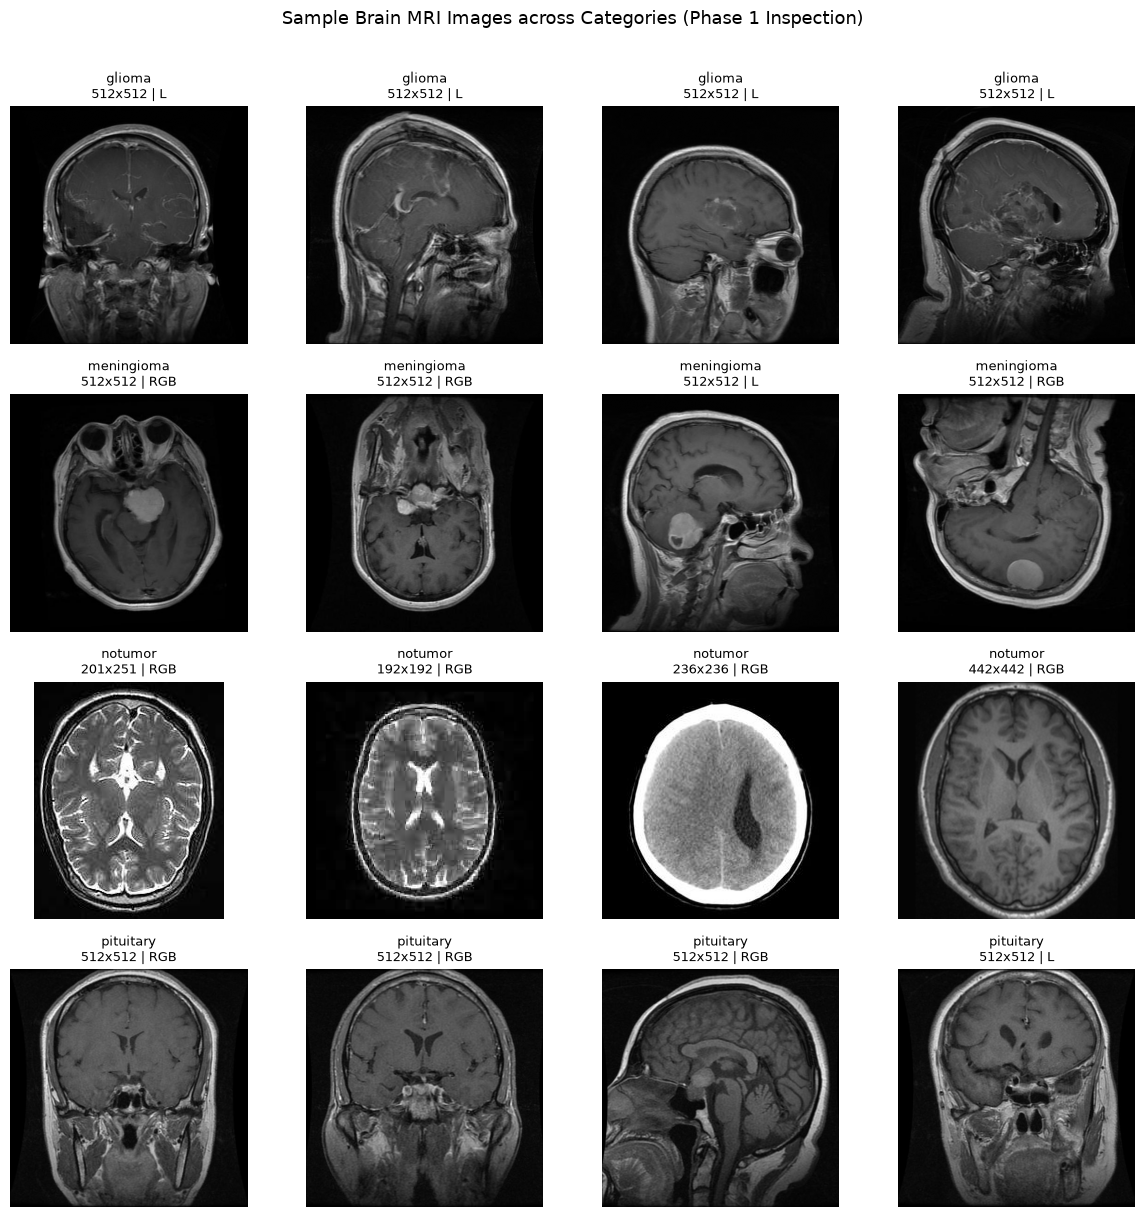

In [7]:
fig, axes = plt.subplots(4, 4, figsize=(12, 12))

for r, cat in enumerate(CATEGORIES):
    cat_files = [p for s, c, p in all_image_paths if s == "Training" and c == cat]
    selected_files = cat_files[:4]
    
    for c, img_path in enumerate(selected_files):
        ax = axes[r, c]
        img = Image.open(img_path)
        ax.imshow(img, cmap="gray" if img.mode == "L" else None)
        ax.set_title(f"{cat}\n{img.size[0]}x{img.size[1]} | {img.mode}", fontsize=9)
        ax.axis("off")

plt.suptitle("Sample Brain MRI Images across Categories (Phase 1 Inspection)", fontsize=13, y=1.01)
plt.tight_layout()
plt.show()


## 7. Key Observations & Restoration Scope Implications

1. **Dataset Balance:**
   - Perfect balance across classes: exactly 1,400 training and 400 testing images per category (7,200 total images).
   - `notumor` contains 1,400 training and 400 testing images (1,800 clean reference images).

2. **File Integrity:**
   - 100% of images are intact and readable; 0 corrupted files.
   - 0 duplicate filenames across splits.

3. **Color Space & Channel Diversity:**
   - The dataset contains mixed modes: 4,129 RGB, 3,067 Grayscale (L), 3 RGBA, and 1 Palette (P).
   - In `notumor`, 1,767 are RGB and 29 are Grayscale.
   - **Implication for Restoration:** All images should be systematically converted to single-channel Grayscale (or normalized uniformly) during preprocessing to maintain scientific consistency for MRI degradation and restoration models.

4. **Resolution Diversity:**
   - 447 distinct dimensions exist, ranging from 175x167 up to 1375x1446.
   - The dominant resolution is 512x512 (5,014 images, ~70% of dataset).
   - **Implication for Restoration:** Consistent spatial standardization (e.g., resizing or central crop to 256x256 or 512x512) will be required for neural network batch training.

5. **Pixel Dynamic Range:**
   - All images use standard 8-bit unsigned integer depth `uint8` with values spanning `[0, 255]`.
